In [7]:
from pyprojroot import here
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
# params
path_raw = here() / "data" / "raw"
path_img = path_raw / "Images"

In [9]:
df = pl.read_csv(path_raw / "Labels.csv").drop("")
df.head()

Image Name,Patient,Label,Quality Score
str,i64,str,f64
"""0_0.jpg""",0,"""GON+""",6.18
"""1_0.jpg""",1,"""GON+""",5.31
"""1_1.jpg""",1,"""GON+""",4.37
"""2_0.jpg""",2,"""GON+""",3.51
"""2_1.jpg""",2,"""GON+""",4.24


# Labels distribution

Label
GON+     0.733601
GON-     0.266399
Name: proportion, dtype: float64

Text(0.5, 1.0, 'Distribution of Labels')

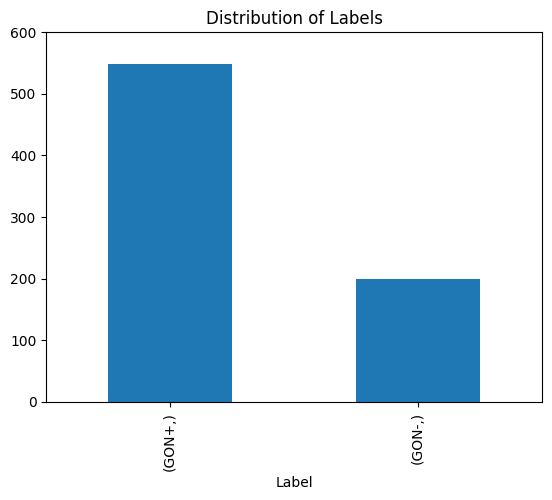

In [10]:
tmp_df = df.select(pl.col("Label")).to_pandas()
display(tmp_df.value_counts(normalize=True))
tmp_df.value_counts().plot.bar()
plt.ylim((0, 600))
plt.title("Distribution of Labels")

# Quality score Distribution

(0.0, 10.0)

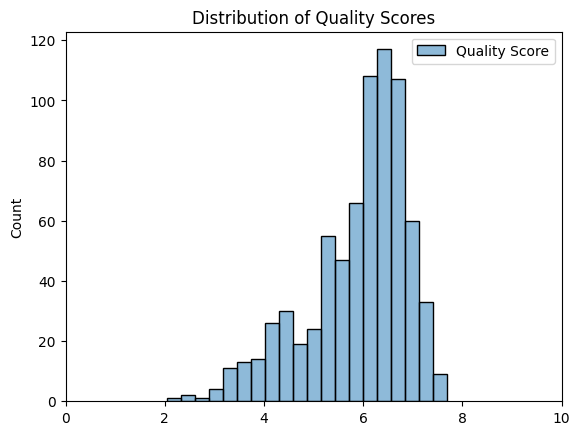

In [11]:
tmp_df = df.select('Quality Score')
sns.histplot(tmp_df.to_pandas(), bins=20)
plt.title("Distribution of Quality Scores")
plt.xlim((0, 10))

# Same patient with different image exists?
> There are many patient with multiple images

In [12]:
df.select(pl.col("Patient").value_counts()).unnest("Patient").filter(
    pl.col("count") > 1
)

Patient,count
i64,u32
103,2
91,8
239,2
42,4
18,5
…,…
151,5
189,3
180,6


# Same patient with different labels
> Same patient has same GON label even it has multiple images

In [34]:
df.group_by(pl.col("Patient")).agg(pl.col("Label").value_counts()).explode(
    "Label"
).unnest("Label").select(pl.col("Patient").is_duplicated().any())

Patient
bool
false


# Quality vs labels
> GON+ and GON- has similar image quality distribution

In [ ]:
tmp_df = df.select("Quality Score", "Label").to_pandas()
sns.kdeplot(
    tmp_df,
    x="Quality Score",
    hue="Label",
)